In [11]:
#  Import Libraries
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.decomposition import PCA

In [12]:
#  Load the Dataset
file_path = r'data/lcs_synthetic_20000.csv'
data = pd.read_csv(file_path)

In [13]:
#  Preprocess the Dataset
data.columns = data.columns.str.strip()
data['GENDER'] = data['GENDER'].map({'M': 1, 'F': 0})

binary_cols = ['SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE',
               'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING',
               'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN']
for col in binary_cols:
    data[col] = data[col].map({1: 0, 2: 1})

data['LUNG_CANCER'] = data['LUNG_CANCER'].map({'YES': 1, 'NO': 0})

In [14]:
# Split Features and Target
X = data.drop('LUNG_CANCER', axis=1)
y = data['LUNG_CANCER']

In [15]:
#  Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [16]:
#  Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
# 1. Basic model: KNN with default k=5
basic_knn = KNeighborsClassifier(n_neighbors=5)
basic_knn.fit(X_train_scaled, y_train)
basic_pred = basic_knn.predict(X_test_scaled)
basic_acc = accuracy_score(y_test, basic_pred)
print(f"Basic Model Accuracy: {basic_acc:.4f}")

Basic Model Accuracy: 0.8605


In [18]:
# 2. Improved model: Tune k (1-20)
param_grid_improved = {'n_neighbors': range(1, 21)}
improved_knn = GridSearchCV(KNeighborsClassifier(), param_grid_improved, cv=5, scoring='accuracy')
improved_knn.fit(X_train_scaled, y_train)
improved_pred = improved_knn.predict(X_test_scaled)
improved_acc = accuracy_score(y_test, improved_pred)
print(f"Improved Model Accuracy: {improved_acc:.4f} (Best k: {improved_knn.best_params_['n_neighbors']})")

Improved Model Accuracy: 0.8715 (Best k: 17)


In [19]:
# 3. More improved model: Tune k, weights, and metric
param_grid_more = {
    'n_neighbors': range(1, 21),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
more_knn = GridSearchCV(KNeighborsClassifier(), param_grid_more, cv=5, scoring='accuracy')
more_knn.fit(X_train_scaled, y_train)
more_pred = more_knn.predict(X_test_scaled)
more_acc = accuracy_score(y_test, more_pred)
print(f"More Improved Model Accuracy: {more_acc:.4f} (Best params: {more_knn.best_params_})")

More Improved Model Accuracy: 0.8715 (Best params: {'metric': 'euclidean', 'n_neighbors': 17, 'weights': 'uniform'})


In [20]:
y_pred_more = more_knn.predict(X_test_scaled)

print("\n More Improved KNN Metrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_more):.2f}")
print(f"Precision: {precision_score(y_test, y_pred_more):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_more):.2f}")
print(f"F1 Score: {f1_score(y_test, y_pred_more):.2f}")
print(f"ROC AUC: {roc_auc_score(y_test, more_knn.predict_proba(X_test_scaled)[:, 1]):.2f}")


 More Improved KNN Metrics:
Accuracy: 0.87
Precision: 0.87
Recall: 1.00
F1 Score: 0.93
ROC AUC: 0.52


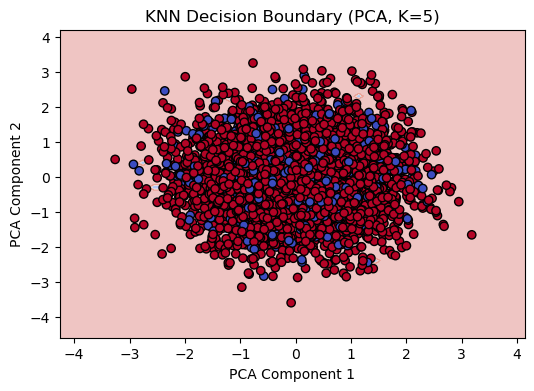

In [21]:
#Visualize Decision Boundary with PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

model_knn_pca = KNeighborsClassifier(n_neighbors=5).fit(X_train_pca, y_train)

x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = model_knn_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(6, 4))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='coolwarm', edgecolors='k')
plt.title("KNN Decision Boundary (PCA, K=5)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

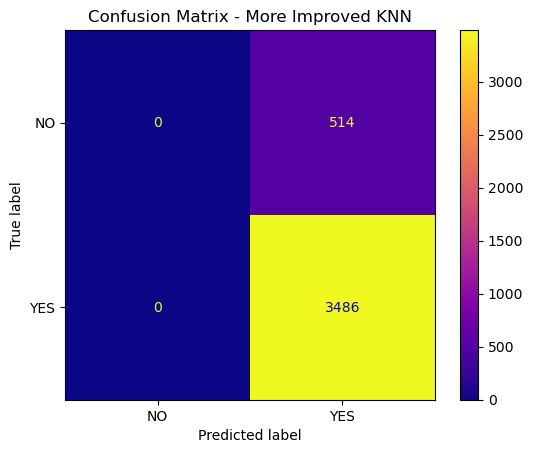

In [22]:
#Confusion Matrix for More Improved Model
cm = confusion_matrix(y_test, more_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NO', 'YES'])
disp.plot(cmap=plt.cm.plasma)
plt.title("Confusion Matrix - More Improved KNN")
plt.show()

In [23]:
# Experiment with Different K Values
for k in [1, 5, 10]:
    model_knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    y_pred_knn = model_knn.predict(X_test_scaled)
    print(f"\nKNN (K={k}) Metrics:")
    print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.2f}, F1: {f1_score(y_test, y_pred_knn):.2f}")


KNN (K=1) Metrics:
Accuracy: 0.78, F1: 0.88

KNN (K=5) Metrics:
Accuracy: 0.86, F1: 0.92

KNN (K=10) Metrics:
Accuracy: 0.87, F1: 0.93
